<a href="https://colab.research.google.com/github/MrAkash03/Goal-Oriented-Maze-Solve/blob/main/Q_Learning_Maze_(RL).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Imports**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

**Create Maze**

In [ ]:
maze_1 = np.array([
    [0,0,0,0,0],
    [1,1,0,1,0],
    [0,0,0,1,0],
    [0,1,0,0,0],
    [0,0,0,1,0]
])

maze_2 = np.array([
    [0,0,0,1,0],
    [0,1,0,1,0],
    [0,1,0,0,0],
    [0,1,1,1,0],
    [0,0,0,0,0]
])

maze_3 = np.array([
    [0,0,1,0,0],
    [0,0,1,0,1],
    [0,0,0,0,1],
    [1,1,1,0,0],
    [0,0,0,0,0]
])

MAZES = [
    maze_1,
    maze_2,
    maze_3
]

print(maze_1)
print(maze_2)
print(maze_3)

[[0 0 0 0 0]
 [1 1 0 1 0]
 [0 0 0 1 0]
 [0 1 0 0 0]
 [0 0 0 1 0]]
[[0 0 0 1 0]
 [0 1 0 1 0]
 [0 1 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
[[0 0 1 0 0]
 [0 0 1 0 1]
 [0 0 0 0 1]
 [1 1 1 0 0]
 [0 0 0 0 0]]


/tmp/ipykernel_829/1501532670.py:4: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  free_patch = mpatches.Patch(color='white', label='0 = Free Cell', edgecolor='black')


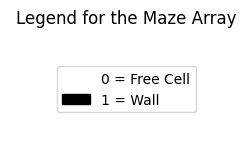

In [ ]:
import matplotlib.patches as mpatches

# Create a legend to explain the cell values
free_patch = mpatches.Patch(color='white', label='0 = Free Cell', edgecolor='black')
wall_patch = mpatches.Patch(color='black', label='1 = Wall')

plt.figure(figsize=(3, 1.5))
plt.legend(handles=[free_patch, wall_patch], loc='center', frameon=True)
plt.axis('off')
plt.title("Legend for the Maze Array")
plt.show()

**Random Maze Selection**

In [ ]:
def get_random_maze():

    idx = np.random.randint(
        len(MAZES)
    )

    return MAZES[idx]

In [ ]:
for i in range(10):

    maze = get_random_maze()

    print(
        np.array_equal(maze, maze_1),
        np.array_equal(maze, maze_2),
        np.array_equal(maze, maze_3)
    )

False False True
False True False
False True False
False True False
True False False
False True False
False False True
False True False
False False True
True False False


**Environment Variables**

In [ ]:
ROWS = maze_1.shape[0]
COLS = maze_1.shape[1]


actions = [
    (-1, 0),   # up
    (1, 0),    # down
    (0, -1),   # left
    (0, 1)     # right
]

NUM_ACTIONS = len(actions)
NUM_STATES = (
    ROWS
    * COLS
    * ROWS
    * COLS
)


**State Conversion**

In [ ]:
def state_to_index(
    row,
    col,
    goal_row,
    goal_col
):

    return (
        row
        + ROWS * col
        + ROWS * COLS * goal_row
        + ROWS * COLS * ROWS * goal_col
    )

**Q Table**

In [ ]:
Q = np.zeros(
    (
        NUM_STATES,
        NUM_ACTIONS
    )
)

**Hyperparameters**

In [ ]:
learning_rate = 0.1

gamma = 0.95

epsilon = 1.0

epsilon_decay = 0.995

epsilon_min = 0.01

episodes = 10000

max_steps = 100


**Environment Step Function**

In [ ]:
def take_action(state, action, goal):

    r, c = state

    dr, dc = actions[action]

    nr = r + dr
    nc = c + dc

    if nr < 0 or nr >= ROWS or nc < 0 or nc >= COLS:

        return state, -10, False

    if maze[nr, nc] == 1:

        return state, -10, False

    new_state = (nr, nc)

    if new_state == goal:

        return new_state, 100, True

    return new_state, -1, False

**Random Start Generator**

In [ ]:
def get_random_start():

    while True:

        r = np.random.randint(ROWS)
        c = np.random.randint(COLS)

        pos = (r,c)

        if maze[r,c] == 0:
            return pos

**Random Goal Generator**

In [ ]:
def get_random_goal(start_pos):

    while True:

        r = np.random.randint(ROWS)
        c = np.random.randint(COLS)

        pos = (r, c)

        if maze[r,c] == 0:
            return pos

**Train Q-Learning**

In [ ]:
rewards_history = []

for episode in range(episodes):

    maze = get_random_maze()

    start_position = get_random_start()

    goal = get_random_goal(
      start_position
   )

    state = start_position

    total_reward = 0

    done = False

    for step in range(max_steps):

        state_idx = state_to_index(
          state[0],
          state[1],
          goal[0],
          goal[1]
        )

        if np.random.rand() < epsilon:

            action = np.random.randint(
                NUM_ACTIONS
            )

        else:

            action = np.argmax(
                Q[state_idx]
            )

        next_state, reward, done = take_action(
            state,
            action,
            goal
        )

        next_state_idx = state_to_index(
          next_state[0],
          next_state[1],
          goal[0],
          goal[1]
        )

        Q[state_idx, action] += (
            learning_rate
            * (
                reward
                +
                gamma * np.max(
                    Q[next_state_idx]
                )
                -
                Q[state_idx, action]
            )
        )

        state = next_state

        total_reward += reward

        if done:
            break

    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )

    rewards_history.append(
        total_reward
    )

**Learning Curve**

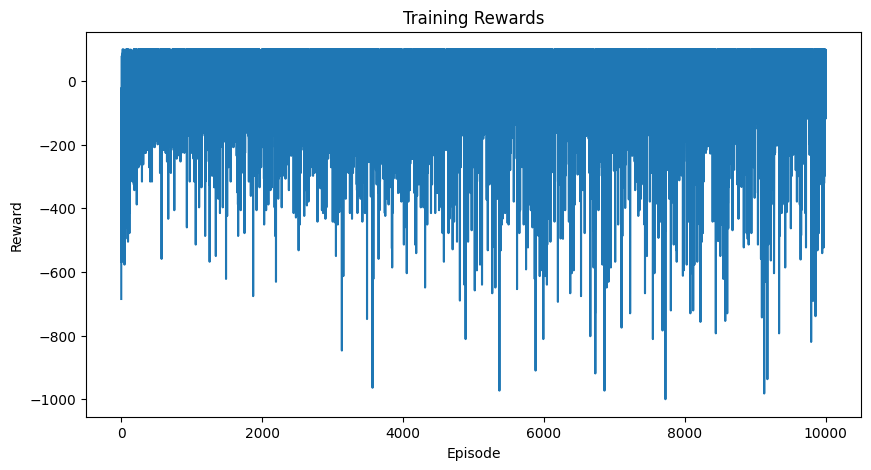

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    rewards_history
)

plt.title(
    "Training Rewards"
)

plt.xlabel(
    "Episode"
)

plt.ylabel(
    "Reward"
)

plt.show()

**Test Agent**

In [ ]:
maze = get_random_maze()

start_position = get_random_start()

goal = get_random_goal(
    start_position
)

state = start_position

path = [state]

done = False

for _ in range(50):

    state_idx = state_to_index(
      state[0],
      state[1],
      goal[0],
      goal[1]
    )

    action = np.argmax(
        Q[state_idx]
    )

    state, reward, done = take_action(
        state,
        action,
        goal
    )

    path.append(
        state
    )

    if done:
        break

print("Reached Goal:", done)
print("Steps:", len(path))

Reached Goal: False
Steps: 51


**Visualize Learned Path**

Start: (2, 0)
Goal: (2, 2)
Start: (2, 0)
Goal: (2, 2)


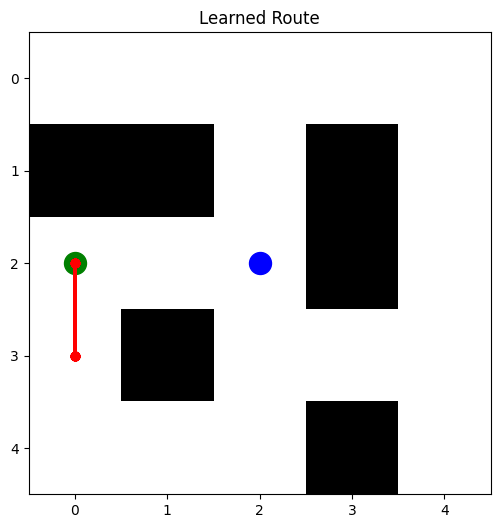

In [ ]:
plt.figure(figsize=(6,6))

plt.imshow(
    maze,
    cmap="binary"
)

rows = [p[0] for p in path]
cols = [p[1] for p in path]

plt.plot(
    cols,
    rows,
    'r-o'
)

print("Start:", start_position)
print("Goal:", goal)

plt.scatter(
    start_position[1],
    start_position[0],
    color='green',
    s=250
)

plt.scatter(
    goal[1],
    goal[0],
    color='blue',
    s=250
)

print("Start:", start_position)
print("Goal:", goal)

plt.title(
    "Learned Route"
)

plt.show()

**Measure Success Rate**

In [ ]:
success = 0

trials = 100

for _ in range(trials):

    start = get_random_start()

    goal = get_random_goal(
      start
    )

    state = start

    done = False

    for _ in range(50):

        state_idx = state_to_index(
        state[0],
        state[1],
        goal[0],
        goal[1]
      )

        action = np.argmax(
            Q[state_idx]
        )

        state, reward, done = take_action(
            state,
            action,
            goal
        )

        if done:
            success += 1
            break

print(
    f"Success Rate: {success/trials*100:.2f}%"
)

Success Rate: 53.00%
